In [2]:
import torch 
import torch.nn as nn 
import torch.optim as optim 
from torchvision.datasets import MNIST 
from torchvision import transforms
from torch.utils.data import DataLoader

In [4]:
transform= transforms.Compose([
    transforms.ToTensor(), 
    transforms.Normalize((0.1307,),(0.3081))
])

In [6]:
trainset= MNIST(root="./data", train=True, download=True, transform= transform)
testset= MNIST(root="./data", train=False, download=True, transform= transform)

In [8]:
trainloader= DataLoader(trainset, batch_size=128, shuffle=True) 
testloader= DataLoader(testset, batch_size=128, shuffle= False)

In [10]:
images, labels= next(iter(testloader))

print(images.shape)
print(labels.shape)

torch.Size([128, 1, 28, 28])
torch.Size([128])


In [12]:
# Building RNN 
class RNN(nn.Module): 
    def __init__(self, input_size= 28, hidden_size=128, num_layers=1, num_classes=10): # we are taking 1 row= 1 tmestep ,and each row has 28 pixels
        super().__init__()

        self.hidden_size= hidden_size 
        self.num_layers= num_layers 

        self.rnn= nn.RNN(
            input_size,
            hidden_size, 
            num_layers,
            batch_first= True # Normally PyTorch expects:(seq_len, batch_size, input_size) but here we are using (batch_size, seq_len, input_size).
        )

        self.fc= nn.Linear( # many to many architecture, also this takes 128 features[virtical, horizontal,...] and convert them into 10 final no.s acting as the probability of 0 to 9 for each image.
            hidden_size, 
            num_classes 
        )

    def forward(self, x): 
        h0= torch.zeros(
            self.num_layers, 
            x.size(0), 
            self.hidden_size
        )
        out, _= self.rnn(x, h0) # this takes [64,28,28] & gives [64 images, 28 timesteps, 128 memory value] all for one batch
        out= self.fc(out[:,-1,:]) # this means [all images, last timestep, all memory values]-> [64,128] will be passed and 10 values will be given by "fc"

        return out

In [14]:
model= RNN()
criterion= nn.CrossEntropyLoss() 
optimizer= optim.Adam(model.parameters(), lr=0.001) # model.para()-this explicitly passes "w" and "b" to adam for tweek.
# lr=0.001 is ideal starting learning rate.

In [16]:
# Training
epochs= 5
epoch_loss=0

for epoch in range(epochs):
    model.train()

    for images, labels in trainloader: 
        optimizer.zero_grad() 
        images= images.squeeze(1) # since model dosent need channel dimension so will remove from index-1 [64,1,28,28].
        output= model(images) 

        loss=criterion(output, labels)
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item() # loss for a full epoch instead of last batch
        
    print(f"epoch={epoch+1}/{epochs} & loss={epoch_loss/len(trainloader)}")

epoch=1/5 & loss=0.8234654870877134
epoch=2/5 & loss=1.1375594075554725
epoch=3/5 & loss=1.342445473291917
epoch=4/5 & loss=1.5061324571590942
epoch=5/5 & loss=1.6424549216194066


In [18]:
total_val=0 
correct=0 

model.eval() 
with torch.no_grad():  

    for images, labels in testloader: 
        images=images.squeeze(1) 
        outputs= model(images) 

        _,predicted= torch.max(outputs, 1)
        correct+= (predicted==labels).sum().item()

        total_val+= labels.size(0) 
print(f"Accuracy={100*correct/total_val:.2f}%")

Accuracy=96.22%


In [20]:
torch.save(model.state_dict(),"rnn_model.pth")

In [22]:
from sklearn.metrics import confusion_matrix 
import seaborn as sns 
import matplotlib.pyplot as plt

In [39]:
all_preds=[]
all_labels=[] 

model.eval() 
with torch.no_grad(): 
    for image, labels in testloader: 
        image= image.squeeze(1)
        output = model(image)
        _,pred= torch.max(output,1)

        all_preds.extend(pred.numpy())
        all_labels.extend(labels.numpy())

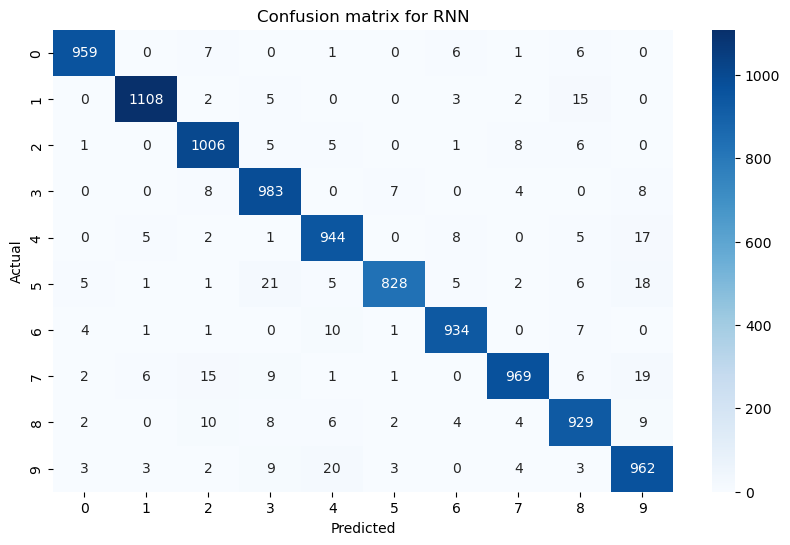

In [53]:
cm= confusion_matrix(all_labels,all_preds)

plt.figure(figsize=(10,6))
sns.heatmap(
    cm,
    annot=True, 
    fmt="d", 
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual") 
plt.title("Confusion matrix for RNN")

plt.show()

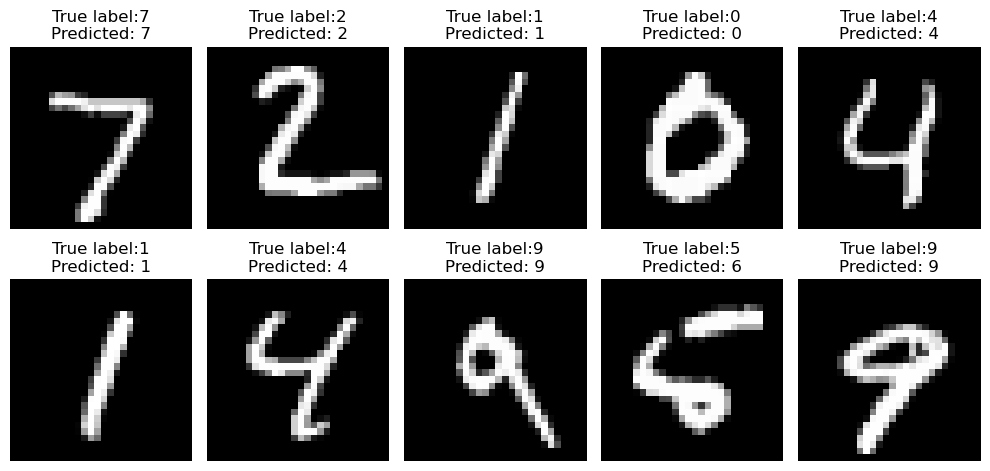

In [83]:
# visualising 
model.eval()
image, labels= next(iter(testloader))
with torch.no_grad(): 
    image= image.squeeze(1)
    output= model(image) 
    _,pred= torch.max(output, 1) 

fig, axes= plt.subplots(2,5, figsize=(10,5))

for i ,ax in enumerate(axes.flat): 
    ax.imshow(image[i].squeeze(1), cmap="gray")
    ax.set_title(f"True label:{labels[i]}\nPredicted: {pred[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()